In [2]:
from google.colab import drive
drive.mount('/content/drive')
import os, sys, glob, json, shutil, time, subprocess, importlib, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

ROOT   = "/content/drive/MyDrive/dtn_project"
RES_A  = f"{ROOT}/results"
RES_B  = f"{ROOT}/results_b"
LOCAL  = "/content/processed"
WINDOW, SEED = 12, 0
DATASETS = ["5g", "4g", "operator"]
COLSET = {"5g": "single", "4g": "single", "operator": "value+daily"}
NEURAL = ["lstm", "gru", "bilstm", "conv1d"]
N_CALLS = 500
if not os.path.exists(LOCAL): shutil.copytree(f"{ROOT}/processed", LOCAL)
sys.path.append(ROOT + "/src")
import torch, neural
torch.set_num_threads(1)
print("Device:", neural.DEVICE)
assert neural.DEVICE == "cpu", "Switch the runtime to CPU (Runtime > Change runtime type), then run again."
def tag(df):
    p = df.run_id.str.split("|")
    df["dataset"], df["colset"], df["window"], df["model"] = p.str[0], p.str[1], p.str[2], p.str[3]
    return df

Mounted at /content/drive
Device: cpu


## 2. Accuracy over all traces (the y-axis of the plot)
For every model: mean RMSE over **all traces** of the dataset (neural: first averaged over the 3 seeds per trace), MAE, median R², direction accuracy. Direction accuracy is not applicable to last value (it never predicts a change).


In [3]:
na = tag(pd.read_csv(f"{RES_A}/neural_trace_results.csv"))
na = na[(na.colset == na.dataset.map(COLSET)) & (na.window == f"w{WINDOW}")]
na = na.groupby(["dataset", "model", "trace"], as_index=False)[["MAE", "RMSE", "R2", "dir_acc"]].mean()   # mean over seeds
nb = tag(pd.read_csv(f"{RES_B}/baseline_trace_results.csv"))
ar = tag(pd.read_csv(f"{RES_B}/arima_trace_results.csv"))
allr = pd.concat([na, nb[["dataset", "model", "trace", "MAE", "RMSE", "R2", "dir_acc"]],
                  ar[["dataset", "model", "trace", "MAE", "RMSE", "R2", "dir_acc"]]])
allr.loc[allr.model == "last_value", "dir_acc"] = np.nan
ACC = allr.groupby(["dataset", "model"]).agg(RMSE=("RMSE", "mean"), MAE=("MAE", "mean"), R2_median=("R2", "median"),
                                             dir_acc=("dir_acc", "mean"), traces=("trace", "nunique")).reset_index()
print(ACC.round(3).to_string(index=False))

 dataset          model     RMSE      MAE  R2_median  dir_acc  traces
      4g          arima 3287.851 2233.071      0.622    0.600     134
      4g         bilstm 3294.491 2248.928      0.614    0.579     134
      4g         conv1d 3277.317 2235.066      0.631    0.586     134
      4g            gru 3279.344 2232.588      0.628    0.580     134
      4g     last_value 3429.096 2268.447      0.593      NaN     134
      4g           lstm 3286.527 2244.676      0.618    0.577     134
      5g          arima 8605.075 4796.878      0.196    0.620      79
      5g         bilstm 7843.485 4310.465      0.086    0.624      79
      5g         conv1d 8096.221 4727.087      0.016    0.606      79
      5g            gru 7900.200 4509.970      0.042    0.624      79
      5g     last_value 9352.828 4572.245     -0.136      NaN      79
      5g           lstm 7868.564 4472.215      0.086    0.630      79
operator          arima   14.963    8.229      0.970    0.511      55
operator         bil

## 3. Inference time per prediction (CPU, one thread)
- **Neural:** one real test window goes through the model; time includes creating the tensor. Median of 500 calls after a warm-up.
- **ARIMA:** fit on one training trace, then for 100 steps: take in the new value (a Kalman update, no refit) and forecast one step ahead.
- **Last value / seasonal naive:** one lookup.

Times are in **milliseconds**.

In [4]:
def load_first_trace(ds):
    d = f"{LOCAL}/{ds}"; sc = json.load(open(f"{d}/scaler.json"))
    names = {"5g": ["DL_bitrate"], "4g": ["DL_bitrate"], "operator": None}[ds]
    cols = list(range(len(sc["cols"]))) if names is None else [sc["cols"].index(n) for n in names]
    f = sorted(glob.glob(d + "/*.npz"))[0]; z = np.load(f)
    tr, va, te = (z[s][:, cols].astype("float32") for s in ("train", "val", "test"))
    w = np.lib.stride_tricks.sliding_window_view(np.vstack([va[-WINDOW:], te]), (WINDOW, te.shape[1]))[:-1, 0]
    return f, tr, va, te, w

def time_calls(fn, n, warm=20):
    for i in range(warm): fn(i)
    t = []
    for i in range(n):
        t0 = time.perf_counter(); fn(i); t.append(time.perf_counter() - t0)
    return float(np.median(t)) * 1000       # ms

lat = {}
for ds in DATASETS:
    f, tr, va, te, w = load_first_trace(ds)
    for kind in NEURAL:
        m, _ = neural.load_model(f"{RES_A}/models/{ds}__{COLSET[ds]}__{kind}__s{SEED}.pt")
        with torch.no_grad():
            lat[(ds, kind)] = time_calls(lambda i: m(torch.from_numpy(w[i % len(w)][None])).numpy(), N_CALLS)
    buf = np.concatenate([tr[:, 0], va[:, 0], te[:, 0]])
    lat[(ds, "last_value")] = time_calls(lambda i: w[i % len(w)][-1, 0], 20000)
    if ds == "operator":
        lat[(ds, "seasonal_naive")] = time_calls(lambda i: buf[len(buf) - 288 + (i % 100)], 20000)
    print(ds, {k[1]: round(v, 4) for k, v in lat.items() if k[0] == ds})

5g {'lstm': 0.4049, 'gru': 0.5906, 'bilstm': 0.5997, 'conv1d': 0.1178, 'last_value': 0.0005}
4g {'lstm': 0.2978, 'gru': 0.4405, 'bilstm': 0.394, 'conv1d': 0.0998, 'last_value': 0.0008}
operator {'lstm': 0.3026, 'gru': 0.4545, 'bilstm': 0.442, 'conv1d': 0.11, 'last_value': 0.0005, 'seasonal_naive': 0.0003}


In [5]:
# ARIMA: one Kalman update + one-step forecast per step (no refit), on the first trace of each dataset
from statsmodels.tsa.arima.model import ARIMA
order_df = pd.read_csv(f"{RES_B}/arima_order_search.csv")
ORDER = {}
for ds in DATASETS:
    d = order_df[order_df.dataset == ds].sort_values("val_RMSE"); ORDER[ds] = eval(d.iloc[0].order)
for ds in DATASETS:
    f, tr, va, te, w = load_first_trace(ds); o = ORDER[ds]
    res = ARIMA(tr[-20000:, 0].astype("float64"), order=o, trend="c" if o[1] == 0 else "n").fit()
    new = te[:, 0].astype("float64"); state = {"r": res}
    def step(i):
        state["r"] = state["r"].extend(new[i:i + 1]); state["r"].forecast(1)
    lat[(ds, "arima")] = time_calls(step, 100, warm=5)
    print(ds, "arima order", o, "ms per step:", round(lat[(ds, "arima")], 3))

5g arima order (2, 1, 1) ms per step: 5.504
4g arima order (1, 1, 1) ms per step: 3.746
operator arima order (2, 1, 1) ms per step: 3.729


## 4. Memory and model size
Each model is loaded in a **fresh Python process** (CPU only) that makes 200 predictions (ARIMA: fits and makes 50 steps); we measure how much the process's peak memory rises above its memory just before the model was loaded. Repeated 3 times, median. Small differences (about 1 to 2 MB) are noise.

Model size: the saved file size (neural) and the number of parameters.


In [6]:
STATUS = """
def status(key):
    for line in open("/proc/self/status"):
        if line.startswith(key): return int(line.split()[1])      # kB
"""
MEM_NEURAL = STATUS + f"""
import sys, numpy as np, torch
sys.path.insert(0, "{ROOT}/src"); import neural
torch.set_num_threads(1)
before = status("VmRSS")
m, _ = neural.load_model(sys.argv[1]); X = np.random.randn(1, {WINDOW}, int(sys.argv[2])).astype("float32")
with torch.no_grad():
    for _ in range(200): m(torch.from_numpy(X))
print(status("VmHWM") - before)
"""
MEM_ARIMA = STATUS + """
import sys, numpy as np
from statsmodels.tsa.arima.model import ARIMA
before = status("VmRSS")
tr = np.load(sys.argv[1])["train"][:, 0].astype("float64")[-20000:]; o = tuple(int(x) for x in sys.argv[2:5])
r = ARIMA(tr, order=o, trend="c" if o[1] == 0 else "n").fit()
for i in range(50): r = r.extend(tr[i:i + 1]); r.forecast(1)
print(status("VmHWM") - before)
"""
env = dict(os.environ, CUDA_VISIBLE_DEVICES="")
def extra_mb(script, *args):
    v = [float(subprocess.run([sys.executable, "-c", script, *map(str, args)], capture_output=True, text=True,
                              env=env).stdout.strip().split()[-1]) for _ in range(3)]
    return max(0.0, float(np.median(v)) / 1024)

mem, size = {}, {}
for ds in DATASETS:
    f, tr, va, te, w = load_first_trace(ds)
    for kind in NEURAL:
        p = f"{RES_A}/models/{ds}__{COLSET[ds]}__{kind}__s{SEED}.pt"
        mem[(ds, kind)] = extra_mb(MEM_NEURAL, p, w.shape[2])
        size[(ds, kind)] = os.path.getsize(p) / 1024
    o = ORDER[ds]; mem[(ds, "arima")] = extra_mb(MEM_ARIMA, f, *o)
    size[(ds, "arima")] = (o[0] + o[2] + (1 if o[1] == 0 else 0) + 1) * 8 / 1024      # parameters x 8 bytes
    mem[(ds, "last_value")] = mem[(ds, "seasonal_naive")] = 0.0
    size[(ds, "last_value")] = 8 / 1024; size[(ds, "seasonal_naive")] = 288 * 8 / 1024
    print(ds, "extra memory (MB):", {k[1]: round(v, 1) for k, v in mem.items() if k[0] == ds})

5g extra memory (MB): {'lstm': 16.2, 'gru': 12.1, 'bilstm': 16.4, 'conv1d': 10.7, 'arima': 7.2, 'last_value': 0.0, 'seasonal_naive': 0.0}
4g extra memory (MB): {'lstm': 16.3, 'gru': 12.0, 'bilstm': 16.5, 'conv1d': 10.6, 'arima': 7.3, 'last_value': 0.0, 'seasonal_naive': 0.0}
operator extra memory (MB): {'lstm': 16.1, 'gru': 12.1, 'bilstm': 16.4, 'conv1d': 10.5, 'arima': 19.2, 'last_value': 0.0, 'seasonal_naive': 0.0}


## 5. The cost table, the accuracy-vs-cost plot and the best trade-offs
Combines accuracy, training cost, inference time, size and memory into one table (`cost_table.csv`), and draws:
- **Top row:** RMSE against inference time per prediction (log axis). Bigger markers mean bigger models. A **black ring marks the models that are not beaten on both accuracy and speed** (the best trade-offs).
- **Bottom row:** RMSE against training time, for the models that have training (neural, ARIMA). The hardware differs (see top of the notebook), so read this one with care.


 dataset          model      RMSE  R2_median  dir_acc  train_s  train_s_per_trace  infer_ms  size_KB  extra_mem_MB
      4g          arima 3287.8512     0.6225   0.5995  45.6000             0.3406    3.7457   0.0234        7.3047
      4g         bilstm 3294.4912     0.6137   0.5787  11.4333                NaN    0.3940  38.4141       16.5352
      4g         conv1d 3277.3165     0.6306   0.5856   5.2333                NaN    0.0998  17.6338       10.6055
      4g            gru 3279.3438     0.6276   0.5795   7.9000                NaN    0.4405  53.2002       12.0039
      4g     last_value 3429.0957     0.5929      NaN   0.0000                NaN    0.0008   0.0078        0.0000
      4g           lstm 3286.5266     0.6180   0.5774   8.6667                NaN    0.2978  70.0215       16.3086
      5g          arima 8605.0752     0.1959   0.6202 114.9000             1.4546    5.5035   0.0312        7.2031
      5g         bilstm 7843.4850     0.0857   0.6240  16.9000                Na

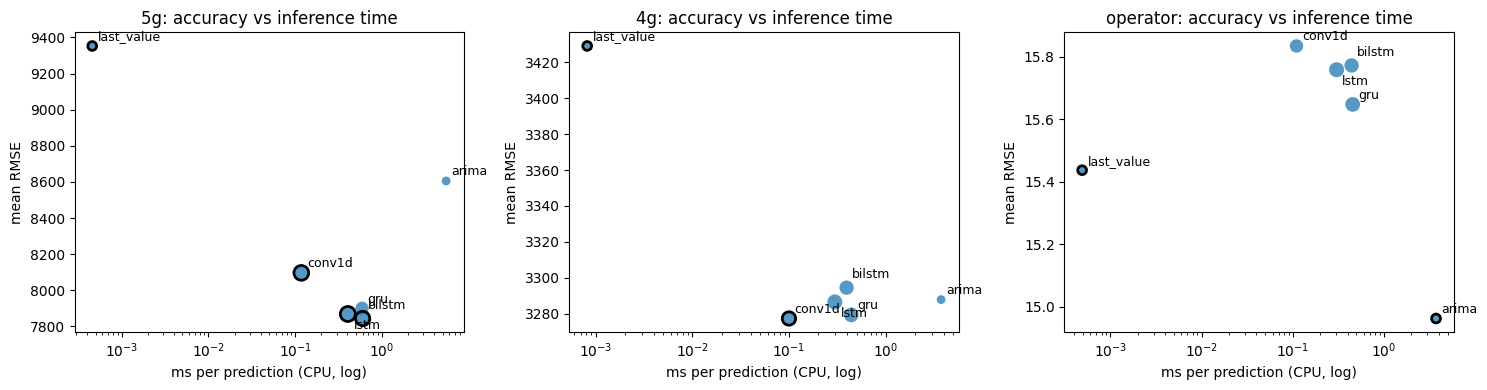

In [11]:
runs = tag(pd.read_csv(f"{RES_A}/neural_runs.csv"))
runs = runs[(runs.colset == runs.dataset.map(COLSET)) & (runs.window == f"w{WINDOW}")]
train_n = runs.groupby(["dataset", "model"]).agg(train_s=("train_s", "mean"), params=("params", "first")).reset_index()
ar_runs = pd.read_csv(f"{RES_B}/arima_runs.csv"); ar_tr = tag(pd.read_csv(f"{RES_B}/arima_trace_results.csv"))
tr_ar = pd.DataFrame([dict(dataset=r.dataset, model="arima", train_s=r.train_s, params=np.nan) for r in ar_runs.itertuples()])
TRAIN = pd.concat([train_n, tr_ar])
fit_per_trace = ar_tr.groupby("dataset").fit_s.mean()

C = ACC.merge(TRAIN, on=["dataset", "model"], how="left")
C["train_s"] = C.train_s.fillna(0.0)
C["train_s_per_trace"] = [fit_per_trace[r.dataset] if r.model == "arima" else np.nan for r in C.itertuples()]
C["infer_ms"] = [lat[(r.dataset, r.model)] for r in C.itertuples()]
C["size_KB"] = [size[(r.dataset, r.model)] for r in C.itertuples()]
C["extra_mem_MB"] = [mem[(r.dataset, r.model)] for r in C.itertuples()]
C.to_csv(f"{RES_B}/cost_table.csv", index=False)
pd.set_option("display.width", 220)
print(C[["dataset", "model", "RMSE", "R2_median", "dir_acc", "train_s", "train_s_per_trace", "infer_ms", "size_KB",
         "extra_mem_MB"]].round(4).to_string(index=False))

def pareto(df):
    keep = []
    for i, a in df.iterrows():
        dom = ((df.RMSE <= a.RMSE) & (df.infer_ms <= a.infer_ms) & ((df.RMSE < a.RMSE) | (df.infer_ms < a.infer_ms))).any()
        keep.append(not dom)
    return df[keep]
print()
for ds in DATASETS: print(f"Best trade-offs (accuracy vs inference time), {ds}:", list(pareto(C[C.dataset == ds]).model))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
offs = {"lstm": (4, -11), "gru": (4, 4), "bilstm": (4, 7), "conv1d": (4, 4)}
for ax, ds in zip(axes, DATASETS):
    d = C[(C.dataset == ds) & (C.model != "seasonal_naive")]; p = pareto(d)
    sz = lambda df: 40 + 18 * np.log1p(df.size_KB)
    ax.scatter(d.infer_ms, d.RMSE, s=sz(d), c="C0", alpha=.75, linewidths=0)
    ax.scatter(p.infer_ms, p.RMSE, s=sz(p), facecolors="none", edgecolors="k", linewidths=2)
    for r in d.itertuples():
        ax.annotate(r.model, (r.infer_ms, r.RMSE), fontsize=9, xytext=offs.get(r.model, (4, 4)), textcoords="offset points")
    ax.set_xscale("log"); ax.set_title(f"{ds}: accuracy vs inference time")
    ax.set_xlabel("ms per prediction (CPU, log)"); ax.set_ylabel("mean RMSE")
plt.tight_layout(); plt.savefig(f"{RES_B}/plot_accuracy_vs_cost_clean.png", dpi=150, bbox_inches="tight"); plt.show()

In [10]:
e2 = pd.read_csv(f"{RES_B}/exp2_summary.csv")
e2 = e2[e2.strategy != "none"].copy()
e2["s_per_retrain"] = [r.retrain_s / (r.retrains * r.traces) if r.retrains > 0 else np.nan for r in e2.itertuples()]
e2["extra_s_per_trace"] = e2.retrain_s / e2.traces
U = e2[["dataset", "model", "strategy", "retrains", "s_per_retrain", "extra_s_per_trace", "d_RMSE_%"]]
U.to_csv(f"{RES_B}/cost_update.csv", index=False)
print(U.round(3).to_string(index=False))

 dataset  model    strategy  retrains  s_per_retrain  extra_s_per_trace  d_RMSE_%
      4g conv1d       adwin      0.05          0.065              0.003    -0.048
      4g conv1d       kswin      1.35          0.065              0.088     0.212
      4g conv1d fixed_adwin      0.05          0.060              0.003     0.000
      4g conv1d fixed_kswin      1.35          0.062              0.083     0.159
      4g    gru       adwin      0.05          0.075              0.004    -0.045
      4g    gru       kswin      1.45          0.084              0.122     0.188
      4g    gru fixed_adwin      0.05          0.076              0.004     0.000
      4g    gru fixed_kswin      1.45          0.083              0.121    -0.046
      5g bilstm       adwin      0.00            NaN              0.000     0.000
      5g bilstm       kswin      1.60          0.115              0.184    -0.397
      5g bilstm fixed_adwin      0.00            NaN              0.000     0.000
      5g bilstm 